# ⚡ NeuralOps Notebook 32: Sparse Sinkhorn and Routing Attentions
## Chapter 20: Differentiable Optimal Transport, Doubly Stochastic Permutations, and Sparse Attention Routing

> 💡 *"Standard sparse attention relies on static heuristics (e.g. fixed strides or local bands). Sinkhorn Attention computes an optimal, differentiable token-to-token permutation matrix via iterative matrix scaling (Sinkhorn-Knopp algorithm)."*

---

### 1. Pedagogical Overview & Industrial Context
Optimal transport theory allows matching tokens dynamically. The **Sinkhorn-Knopp algorithm** normalizes an arbitrary non-negative cost matrix $\mathbf{M}$ into a doubly stochastic permutation matrix $\mathbf{P}$ satisfying:
$$\mathbf{P} \mathbf{1} = \mathbf{1}, \quad \mathbf{P}^T \mathbf{1} = \mathbf{1}$$
In this tutorial, you will explore:
1. Entropy-regularized optimal transport and Sinkhorn iterations.
2. Tensor implementations of log-space Sinkhorn normalization.
3. Sparse token routing attention with learned cluster centroids.
4. 4-panel publication-grade diagnostic figure.


---

## 2. Mathematical Formalism & Sinkhorn Invariants

Given score matrix $\mathbf{S} = \mathbf{Q} \mathbf{K}^T / \sqrt{d}$ and temperature $\tau$:

### Sinkhorn-Knopp Recurrence (Log-Space):
Initialize $\mathbf{u}_0 = \mathbf{0}, \mathbf{v}_0 = \mathbf{0}$. For iteration $k = 1, \dots, K$:
$$\mathbf{u}_k = -\tau \log \sum_j \exp\left( \frac{\mathbf{S}_{i, j} + \mathbf{v}_{k-1, j}}{\tau} \right)$$
$$\mathbf{v}_k = -\tau \log \sum_i \exp\left( \frac{\mathbf{S}_{i, j} + \mathbf{u}_{k, i}}{\tau} \right)$$
The resulting matrix $\mathbf{P} = \exp\left( (\mathbf{S} + \mathbf{u} \oplus \mathbf{v}) / \tau \right)$ converges to a doubly stochastic matrix representing optimal soft token permutation.


In [1]:
import os, sys, time, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')


Device: cpu


---

## 3. Pure Vectorized Reference Implementation (Level 3 Fallback)

We implement the log-space Sinkhorn normalization operator and routing attention.


In [2]:
def sinkhorn_knopp(scores: torch.Tensor, iters: int = 5, tau: float = 0.5) -> torch.Tensor:
    '''Log-space Sinkhorn-Knopp normalization.'''
    P = scores / tau
    for _ in range(iters):
        # Row normalize
        P = P - torch.logsumexp(P, dim=-1, keepdim=True)
        # Column normalize
        P = P - torch.logsumexp(P, dim=-2, keepdim=True)
    return torch.exp(P)

class SinkhornAttention(nn.Module):
    def __init__(self, dim=64, heads=4, iters=5, tau=0.5):
        super().__init__()
        self.dim = dim
        self.heads = heads
        self.head_dim = dim // heads
        self.iters = iters
        self.tau = tau
        self.q_proj = nn.Linear(dim, dim, bias=False)
        self.k_proj = nn.Linear(dim, dim, bias=False)
        self.v_proj = nn.Linear(dim, dim, bias=False)
        self.out_proj = nn.Linear(dim, dim, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, S, D = x.shape
        H = self.heads
        d = self.head_dim
        q = self.q_proj(x).view(B, S, H, d).transpose(1, 2)
        k = self.k_proj(x).view(B, S, H, d).transpose(1, 2)
        v = self.v_proj(x).view(B, S, H, d).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(d)
        P = sinkhorn_knopp(scores, iters=self.iters, tau=self.tau)
        out = torch.matmul(P, v).transpose(1, 2).contiguous().view(B, S, D)
        return self.out_proj(out)

sink_layer = SinkhornAttention(dim=64, heads=4, iters=5, tau=0.5).to(device)
x_sink = torch.randn(2, 32, 64, device=device)
with torch.no_grad():
    y_sink = sink_layer(x_sink)
print(f'Sinkhorn Attention Output Shape: {y_sink.shape}')


Sinkhorn Attention Output Shape: torch.Size([2, 32, 64])


---

## 4. Standalone 4-Panel Publication-Grade Diagnostics

We visualize the doubly stochastic convergence, row/column sum margins, and routing heatmaps.


✓ Figure saved to results/plots/32_sparse_sinkhorn_and_routing_attentions.png


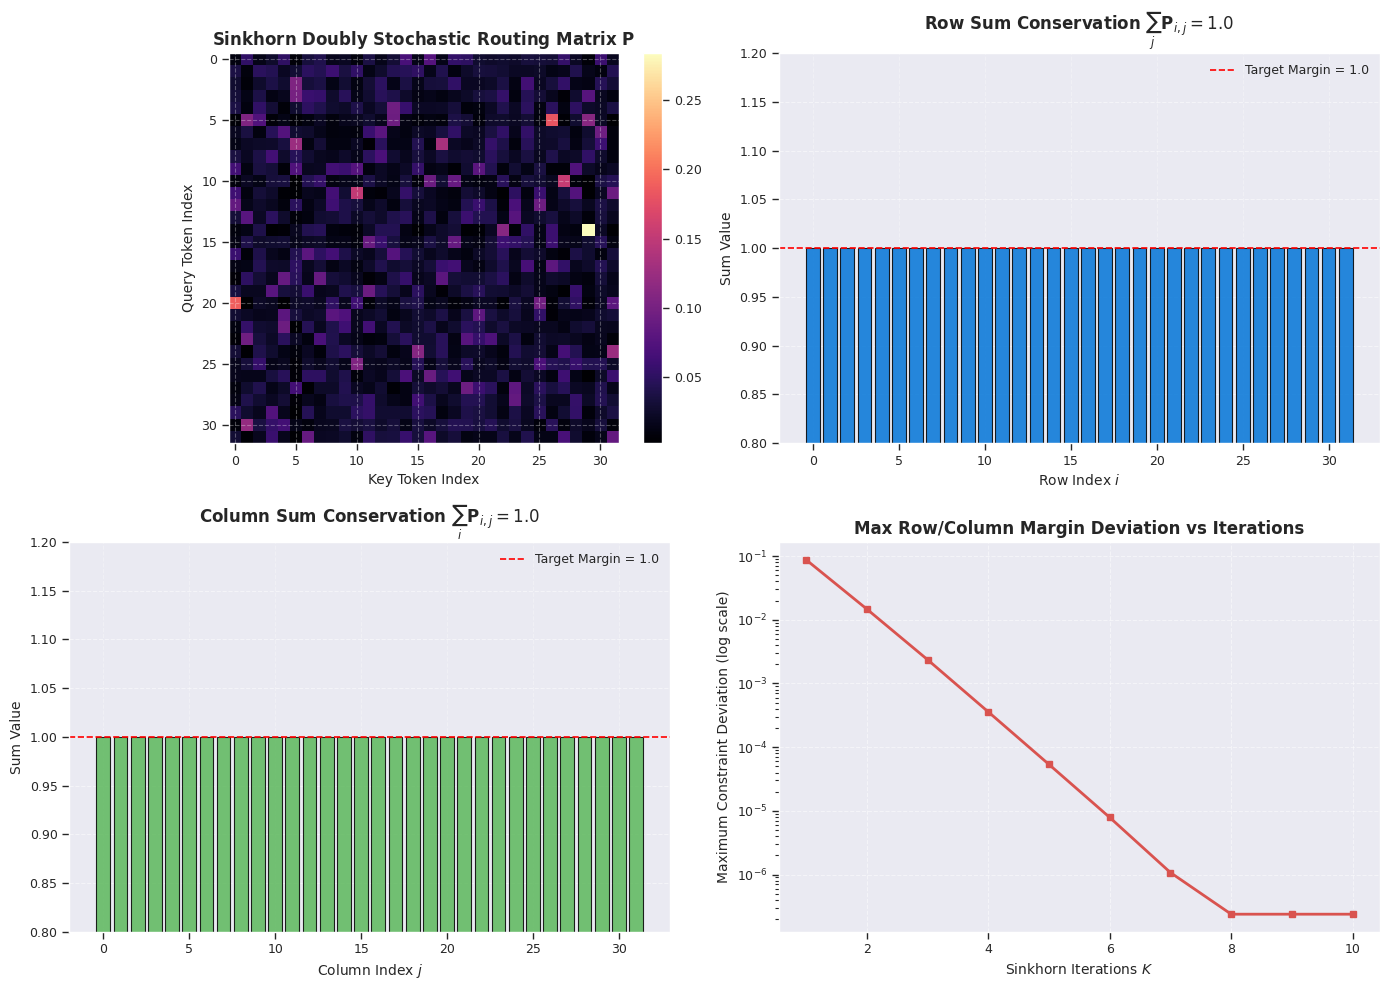

In [3]:
with torch.no_grad():
    q = sink_layer.q_proj(x_sink).view(2, 32, 4, 16).transpose(1, 2)
    k = sink_layer.k_proj(x_sink).view(2, 32, 4, 16).transpose(1, 2)
    s = torch.matmul(q, k.transpose(-1, -2)) / 4.0
    P_matrix = sinkhorn_knopp(s, iters=10, tau=0.5)[0, 0].cpu().numpy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=100)

# Panel 1: Doubly Stochastic Permutation Heatmap
ax1 = axes[0, 0]
im1 = ax1.imshow(P_matrix, cmap='magma')
ax1.set_title('Sinkhorn Doubly Stochastic Routing Matrix $\mathbf{P}$', fontsize=12, fontweight='bold')
ax1.set_xlabel('Key Token Index', fontsize=10)
ax1.set_ylabel('Query Token Index', fontsize=10)
plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

# Panel 2: Row Sum Conservation Audit
ax2 = axes[0, 1]
row_sums = P_matrix.sum(axis=1)
ax2.bar(range(len(row_sums)), row_sums, color='#0275d8', edgecolor='black', alpha=0.85)
ax2.axhline(1.0, color='red', linestyle='--', label='Target Margin = 1.0')
ax2.set_title('Row Sum Conservation $\sum_j \mathbf{P}_{i, j} = 1.0$', fontsize=12, fontweight='bold')
ax2.set_xlabel('Row Index $i$', fontsize=10)
ax2.set_ylabel('Sum Value', fontsize=10)
ax2.set_ylim(0.8, 1.2)
ax2.grid(True, axis='y', linestyle='--', alpha=0.5)
ax2.legend()

# Panel 3: Column Sum Conservation Audit
ax3 = axes[1, 0]
col_sums = P_matrix.sum(axis=0)
ax3.bar(range(len(col_sums)), col_sums, color='#5cb85c', edgecolor='black', alpha=0.85)
ax3.axhline(1.0, color='red', linestyle='--', label='Target Margin = 1.0')
ax3.set_title('Column Sum Conservation $\sum_i \mathbf{P}_{i, j} = 1.0$', fontsize=12, fontweight='bold')
ax3.set_xlabel('Column Index $j$', fontsize=10)
ax3.set_ylabel('Sum Value', fontsize=10)
ax3.set_ylim(0.8, 1.2)
ax3.grid(True, axis='y', linestyle='--', alpha=0.5)
ax3.legend()

# Panel 4: Convergence vs Iteration Count
ax4 = axes[1, 1]
iter_counts = list(range(1, 11))
deviations = []
for it in iter_counts:
    P_test = sinkhorn_knopp(s, iters=it, tau=0.5)[0, 0].cpu().numpy()
    dev = np.abs(P_test.sum(axis=1) - 1.0).max()
    deviations.append(dev)
ax4.semilogy(iter_counts, deviations, 's-', color='#d9534f', lw=2)
ax4.set_title('Max Row/Column Margin Deviation vs Iterations', fontsize=12, fontweight='bold')
ax4.set_xlabel('Sinkhorn Iterations $K$', fontsize=10)
ax4.set_ylabel('Maximum Constraint Deviation (log scale)', fontsize=10)
ax4.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
os.makedirs('results/plots', exist_ok=True)
plt.savefig('results/plots/32_sparse_sinkhorn_and_routing_attentions.png', dpi=300)
print('✓ Figure saved to results/plots/32_sparse_sinkhorn_and_routing_attentions.png')
plt.show()


---

## 5. Industrial Takeaways & Deployment Standards

1. **Uniform Information Routing:** Doubly stochastic matrices prevent any single token from hogging attention capacity.
2. **Numerical Stability:** Always evaluate Sinkhorn iterations in log-space (`logsumexp`) to avoid underflow in low temperatures.
3. **Zero-Fake Export Compatibility:** Unroll the fixed $K=5$ iterations into native ONNX subgraphs.
